In [40]:
import  matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf 
from tensorflow.keras import layers 
from tensorflow.keras.models import Sequential
from tensorflow import keras


In [2]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir  = tf.keras.utils.get_file('flower_photos',origin= dataset_url, cache_dir= '.',untar=True)

In [3]:
data_dir

'.\\datasets\\flower_photos'

In [4]:
data_dir =f'{data_dir}\\flower_photos'

In [5]:
import pathlib
data_dir = pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos/flower_photos')

In [6]:
list(data_dir.glob('**/*.jpg'))

[WindowsPath('datasets/flower_photos/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172636503_21bededa75_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/102841525_bd6628ae3c.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/1031799732_e7f4008c03.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10391248763_1d16681106_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437754174_22ec990b77_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437770546_8bb6f7bdd3_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437929963_bc13eebe0c.jpg'),
 WindowsPath('datasets/flower_photos

In [7]:
image_count = len(list(data_dir.glob('*/*.jpg')))
image_count

3670

In [7]:
roses =  list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

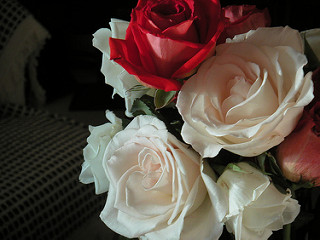

In [8]:
PIL.Image.open(roses[1])

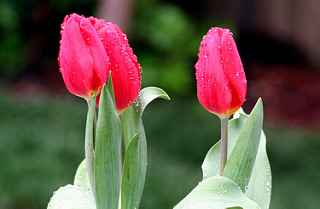

In [9]:
tulips =list(data_dir.glob('tulips/*'))
PIL.Image.open(tulips[0])

In [10]:
flower_images_dict={
    'roses':list(data_dir.glob('roses/*')),
    'daisy':list(data_dir.glob('daisy/*')),
    'dandelion':list(data_dir.glob('dandelion/*')),
    'sunflowers':list(data_dir.glob('sunflowers/*')),
    'tulips': list(data_dir.glob('tulips/*'))
}

In [11]:
flower_images_dict['daisy']

[WindowsPath('datasets/flower_photos/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172636503_21bededa75_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/102841525_bd6628ae3c.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/1031799732_e7f4008c03.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10391248763_1d16681106_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437754174_22ec990b77_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437770546_8bb6f7bdd3_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437929963_bc13eebe0c.jpg'),
 WindowsPath('datasets/flower_photos

In [12]:
flowers_labels_dict ={
    'roses':0,
    'daisy':1,
    'dandelion':2,
    'sunflowers':3,
    'tulips': 4
}

In [13]:
img = cv2.imread(flower_images_dict['roses'][0])
img

array([[[ 0, 15,  6],
        [ 0, 15,  6],
        [ 0, 17,  8],
        ...,
        [24, 51, 31],
        [25, 52, 32],
        [26, 53, 33]],

       [[ 7, 22, 14],
        [ 7, 22, 14],
        [ 6, 21, 13],
        ...,
        [20, 46, 30],
        [23, 49, 33],
        [25, 51, 35]],

       [[12, 23, 15],
        [12, 23, 15],
        [11, 22, 14],
        ...,
        [20, 42, 30],
        [23, 45, 33],
        [26, 48, 36]],

       ...,

       [[19, 30, 27],
        [14, 24, 18],
        [12, 20, 13],
        ...,
        [ 4, 13,  3],
        [ 0,  8,  1],
        [ 0,  5,  0]],

       [[19, 30, 28],
        [18, 27, 24],
        [15, 23, 16],
        ...,
        [ 3, 12,  2],
        [ 1,  9,  2],
        [ 0,  7,  2]],

       [[ 9, 19, 19],
        [17, 25, 24],
        [22, 29, 24],
        ...,
        [ 1, 12,  2],
        [ 2, 10,  3],
        [ 3, 11,  4]]], shape=(240, 179, 3), dtype=uint8)

In [14]:
img.shape

(240, 179, 3)

In [15]:
cv2.resize(img,(180,180)).shape

(180, 180, 3)

In [16]:
# making same dimension for all the images
X,y = [],[]

for flower_name, images in flower_images_dict.items():
    # print(flower_name)
    # print(len(images))
    for image in images :

        img = cv2.imread(image)
        resized_img = cv2.resize(img,(180,180))
        X.append(resized_img)
        y.append(flowers_labels_dict[flower_name])

In [17]:
X[0]

array([[[ 1, 16,  7],
        [ 1, 16,  7],
        [ 1, 17,  9],
        ...,
        [23, 50, 31],
        [25, 51, 32],
        [26, 52, 33]],

       [[10, 23, 15],
        [10, 23, 15],
        [ 9, 22, 14],
        ...,
        [20, 44, 30],
        [23, 47, 33],
        [26, 50, 36]],

       [[13, 20, 13],
        [12, 20, 13],
        [11, 19, 12],
        ...,
        [21, 43, 30],
        [22, 45, 31],
        [25, 48, 34]],

       ...,

       [[12, 24, 18],
        [11, 22, 15],
        [12, 21, 11],
        ...,
        [ 7, 14,  7],
        [ 2,  8,  2],
        [ 0,  2,  0]],

       [[19, 30, 28],
        [16, 26, 21],
        [14, 22, 15],
        ...,
        [ 3, 12,  2],
        [ 0,  8,  1],
        [ 0,  6,  1]],

       [[11, 21, 20],
        [17, 25, 24],
        [21, 28, 23],
        ...,
        [ 1, 12,  2],
        [ 2, 10,  3],
        [ 3, 10,  4]]], shape=(180, 180, 3), dtype=uint8)

In [24]:
# convert to numpy array
X =np.array(X)
y=np.array(y)

In [25]:
# train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=0)

In [26]:
len(X_train)

2752

In [27]:
len(X_test)

918

In [28]:
X[10]

array([[[157, 192, 214],
        [172, 203, 218],
        [204, 234, 239],
        ...,
        [234, 237, 233],
        [243, 235, 240],
        [235, 237, 237]],

       [[158, 185, 197],
        [163, 188, 194],
        [181, 204, 205],
        ...,
        [235, 236, 236],
        [232, 236, 232],
        [237, 237, 239]],

       [[152, 173, 177],
        [147, 165, 166],
        [149, 167, 164],
        ...,
        [242, 241, 237],
        [228, 234, 236],
        [239, 238, 236]],

       ...,

       [[ 96, 116, 133],
        [ 89, 107, 123],
        [ 97, 114, 129],
        ...,
        [ 99, 126, 140],
        [ 92, 118, 132],
        [ 97, 118, 135]],

       [[ 95, 115, 131],
        [ 87, 106, 120],
        [ 88, 105, 118],
        ...,
        [ 93, 119, 133],
        [ 95, 121, 135],
        [ 96, 118, 135]],

       [[ 86, 107, 119],
        [ 78,  96, 107],
        [ 76,  94, 105],
        ...,
        [ 89, 112, 127],
        [ 95, 119, 133],
        [ 94, 116, 134]]

In [29]:
#scaling 
X_train_scaled = X_train/255
X_test_scaled =X_test/255

In [32]:
num_classes=5

# building model
model =Sequential([
    layers.Conv2D(16,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    # Max pooling returns 2 d array , lets flatten it

    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(num_classes)
    
    
])

model.compile(optimizer='adam',
             loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
             metrics=['accuracy'])

model.fit(X_train_scaled,y_train, epochs= 30)

Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 29s 295ms/step - accuracy: 0.4473 - loss: 1.3127
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 24s 278ms/step - accuracy: 0.6195 - loss: 0.9696
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 23s 273ms/step - accuracy: 0.6937 - loss: 0.7938
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 285ms/step - accuracy: 0.7707 - loss: 0.6231
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 26s 297ms/step - accuracy: 0.8681 - loss: 0.3874
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 41s 291ms/step - accuracy: 0.9222 - loss: 0.2393
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 26s 302ms/step - accuracy: 0.9622 - loss: 0.1267
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 290ms/step - accuracy: 0.9822 - loss: 0.0619
Epoch 9/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 293ms/step - accuracy: 0.9876 - loss: 0.0479
Epoch 10/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 28s 329ms/step - accuracy: 0.9964 - loss: 0.0254
Epoch 11/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 30s 352ms/step - accuracy: 0.9967 - loss: 0.0202
Epoch 12/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 28

In [33]:
#evaluate on test data
model.evaluate(X_test_scaled,y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.6656 - loss: 2.1082


[2.10817289352417, 0.6655773520469666]

In [34]:
predictions = model.predict(X_test_scaled)
predictions

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step


array([[  3.6477065 ,  17.784372  ,   0.48502707, -16.935785  ,
         -6.0562215 ],
       [  9.084401  ,   0.38150653,  -6.4173307 ,   0.5966491 ,
          4.873692  ],
       [ -7.691801  ,   0.91698605,  14.17761   , -10.419418  ,
          1.3219514 ],
       ...,
       [  3.4175243 ,  -3.5795445 ,  -8.3687525 ,   2.6471202 ,
          7.089108  ],
       [  8.6010475 ,   3.2826033 ,  -3.8493333 ,   2.3469694 ,
          2.0809715 ],
       [  3.0002248 , -15.661041  ,   3.2255898 ,   7.806717  ,
          3.1705463 ]], shape=(918, 5), dtype=float32)

In [35]:
score = tf.nn.softmax(predictions[0])
score

<tf.Tensor: shape=(5,), dtype=float32, numpy=
array([7.2531054e-07, 9.9999928e-01, 3.0689488e-08, 8.3411681e-16,
       4.4275309e-11], dtype=float32)>

In [36]:
np.argmax(score)

np.int64(1)

In [37]:
y_test[0]

np.int64(1)

In [43]:
# Data augmentation

data_augmentation = keras.Sequential([
    layers.RandomZoom(0.9)
])

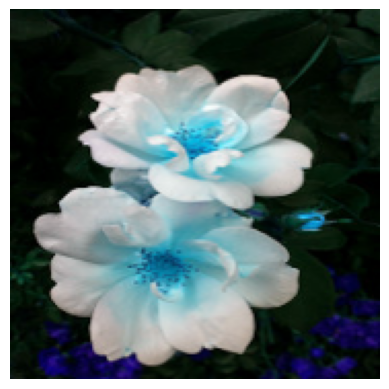

In [45]:
plt.axis('off')
plt.imshow(X[0])

In [46]:
data_augmentation(X[0])

<tf.Tensor: shape=(180, 180, 3), dtype=float32, numpy=
array([[[174.47237 , 197.52486 , 200.27554 ],
        [171.68198 , 197.00029 , 199.97136 ],
        [168.89157 , 196.47572 , 199.66716 ],
        ...,
        [147.6087  , 193.39926 , 196.6748  ],
        [153.00018 , 196.79803 , 200.07356 ],
        [158.39168 , 200.1968  , 203.47234 ]],

       [[174.72382 , 197.60867 , 200.88391 ],
        [172.211   , 197.17664 , 200.57973 ],
        [169.69818 , 196.7446  , 200.27554 ],
        ...,
        [148.18175 , 194.51007 , 198.08978 ],
        [153.48071 , 197.63124 , 201.21097 ],
        [158.7797  , 200.75241 , 204.33214 ]],

       [[174.97525 , 197.69249 , 201.49228 ],
        [172.74002 , 197.35298 , 201.1881  ],
        [170.5048  , 197.01349 , 200.88391 ],
        ...,
        [148.75479 , 195.62085 , 199.50476 ],
        [153.96124 , 198.46445 , 202.34836 ],
        [159.1677  , 201.30806 , 205.19197 ]],

       ...,

       [[ 69.167305, 143.59235 , 158.30026 ],
        [ 71.

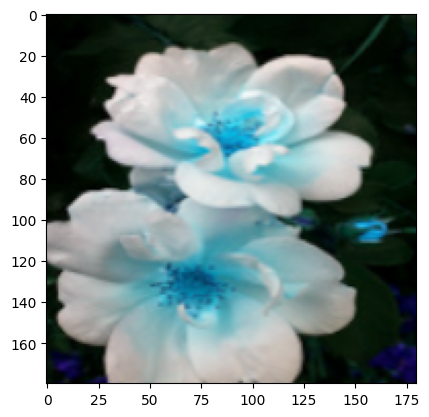

In [51]:
plt.imshow(data_augmentation(X[0]).numpy().astype('uint8'))

In [54]:
img_height = 180
img_width = 180

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizental',
                     input_shape=(img_height,img_width,3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    
])

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [56]:
num_classes =5
model = Sequential([
    data_augmentation,

    layers.Conv2D(16,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding='same',activation='relu'),
    layers.MaxPooling2D(),

    layers.Dropout(0.2),

    layers.Flatten(),

    layers.Dense(128 ,activation='relu'),
    layers.Dense(num_classes)
])

model.compile(optimizer='adam',
             loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
             metrics=['accuracy'])
model.fit(X_train_scaled,y_train,epochs=30)

Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 32s 329ms/step - accuracy: 0.4644 - loss: 1.2531
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 26s 156ms/step - accuracy: 0.6050 - loss: 0.9964
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 157ms/step - accuracy: 0.6475 - loss: 0.9197
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 13s 155ms/step - accuracy: 0.6839 - loss: 0.8249
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.6984 - loss: 0.7736
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 162ms/step - accuracy: 0.7253 - loss: 0.7112
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 167ms/step - accuracy: 0.7427 - loss: 0.6711
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 170ms/step - accuracy: 0.7565 - loss: 0.6359
Epoch 9/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 16s 183ms/step - accuracy: 0.7678 - loss: 0.5990
Epoch 10/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 20s 176ms/step - accuracy: 0.7758 - loss: 0.5803
Epoch 11/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 171ms/step - accuracy: 0.7987 - loss: 0.5329
Epoch 12/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 20

In [57]:
model.evaluate(X_test_scaled,y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7179 - loss: 1.1994


[1.1994315385818481, 0.7178649306297302]